In [ ]:
pip install yfinance pandas pandas_ta matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 1.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 240.3/240.3 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 34.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 32.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 56.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.4/42.4 MB 14.8 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
  Attempting uninstall: llvmlite
    Found existing installation: llvmlite 0.43.0
    Uninstalling llvmlite-0.43.0:
      Successfully uninstalled llvmlite-0.43.0
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.2
    Uninstalling pandas-2.2.2:
      Successfully uninstal

📥 Đang tải dữ liệu BTC-USD...


/tmp/ipython-input-2915579017.py:168: FutureWarning: YF.download() has changed argument auto_adjust default to True
  raw_df = yf.download(TICKER, start=START_DATE, end=END_DATE, progress=False)


🚀 Đang chạy mô phỏng The Cloud Surfer...

KẾT QUẢ BACKTEST: BTC-USD
----------------------------------------
Vốn ban đầu:    $10,000
Vốn cuối cùng:  $35,058
Lợi nhuận:      250.58%
Max Drawdown:   -36.44%
Tổng số lệnh:   63


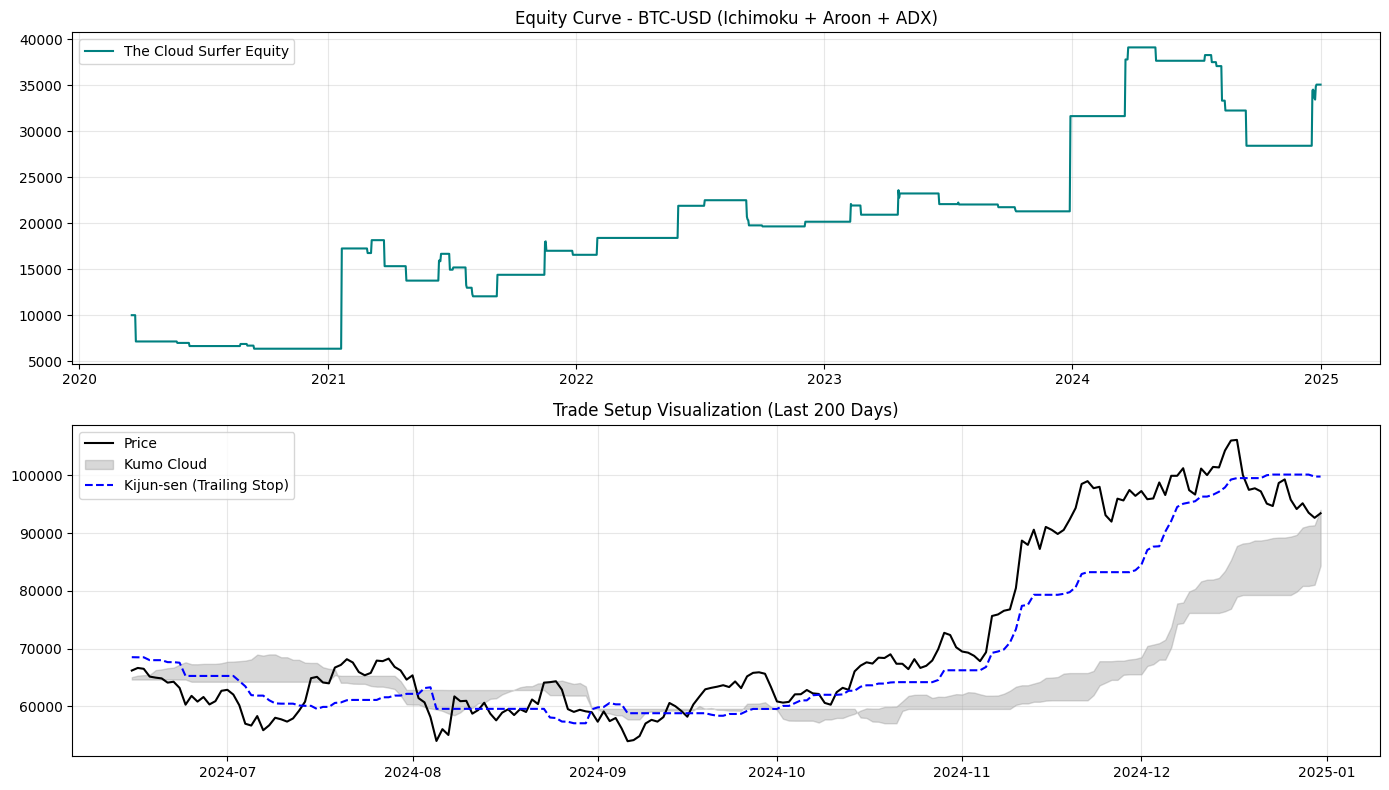


Nhật ký 5 lệnh gần nhất:
          Date  Type         Price            SL              Reason  \
116 2024-12-20  Long  97755.929688  79275.353516                 NaN   
117 2024-12-21  Exit  97224.726562           NaN  Trailing/Stop Loss   
118 2024-12-21  Long  97224.726562  79275.353516                 NaN   
119 2024-12-22  Exit  95104.937500           NaN  Trailing/Stop Loss   
120 2024-12-22  Long  95104.937500  79275.353516                 NaN   
121 2024-12-23  Exit  94686.242188           NaN  Trailing/Stop Loss   
122 2024-12-23  Long  94686.242188  79275.353516                 NaN   
123 2024-12-24  Exit  98676.093750           NaN  Trailing/Stop Loss   
124 2024-12-24  Long  98676.093750  79275.353516                 NaN   
125 2024-12-25  Exit  99299.195312           NaN  Trailing/Stop Loss   

           Equity  
116           NaN  
117  34325.569388  
118           NaN  
119  33577.169581  
120           NaN  
121  33429.347566  
122           NaN  
123  34837.980241  
1

In [ ]:
import yfinance as yf
import pandas as pd
import pandas_ta as ta
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. CẤU HÌNH THAM SỐ (PARAMETERS)
# ==========================================
TICKER = 'BTC-USD'
START_DATE = '2020-01-01'
END_DATE = '2025-01-01'
INITIAL_CAPITAL = 10000

# Tham số Ichimoku (Tiêu chuẩn)
TENKAN_WINDOW = 9
KIJUN_WINDOW = 26
SENKOU_WINDOW = 52
DISPLACEMENT = 26 # Độ trễ của mây

# Tham số Aroon & ADX
AROON_LENGTH = 25
AROON_THRESH = 70
ADX_LENGTH = 14
ADX_THRESH = 25
ADX_EXIT_THRESH = 20 # Thoát khi xu hướng yếu

# ==========================================
# 2. HÀM TÍNH TOÁN CHỈ BÁO (INDICATORS)
# ==========================================
def calculate_cloud_surfer_indicators(df):
    # --- A. ICHIMOKU CLOUD (Tính thủ công để kiểm soát Shift chính xác) ---
    # 1. Tenkan-sen (Conversion Line)
    high_9 = df['High'].rolling(window=TENKAN_WINDOW).max()
    low_9 = df['Low'].rolling(window=TENKAN_WINDOW).min()
    df['tenkan'] = (high_9 + low_9) / 2

    # 2. Kijun-sen (Base Line) - Dùng cho Trailing Stop
    high_26 = df['High'].rolling(window=KIJUN_WINDOW).max()
    low_26 = df['Low'].rolling(window=KIJUN_WINDOW).min()
    df['kijun'] = (high_26 + low_26) / 2

    # 3. Senkou Span A (Leading Span A)
    # Giá trị này được đẩy về tương lai 26 phiên.
    # Để backtest tại thời điểm t, ta cần lấy giá trị đã tính từ t-26
    df['span_a_future'] = ((df['tenkan'] + df['kijun']) / 2)
    df['span_a'] = df['span_a_future'].shift(DISPLACEMENT)

    # 4. Senkou Span B (Leading Span B)
    high_52 = df['High'].rolling(window=SENKOU_WINDOW).max()
    low_52 = df['Low'].rolling(window=SENKOU_WINDOW).min()
    df['span_b_future'] = ((high_52 + low_52) / 2)
    df['span_b'] = df['span_b_future'].shift(DISPLACEMENT)

    # Xác định biên mây tại thời điểm t
    df['cloud_top'] = df[['span_a', 'span_b']].max(axis=1)
    df['cloud_bottom'] = df[['span_a', 'span_b']].min(axis=1)

    # --- B. AROON (Cycle Filter) ---
    # pandas_ta trả về AROOND_25 và AROONU_25
    aroon = df.ta.aroon(length=AROON_LENGTH)
    df['aroon_up'] = aroon[f'AROONU_{AROON_LENGTH}']
    df['aroon_down'] = aroon[f'AROOND_{AROON_LENGTH}']

    # --- C. ADX (Intensity Filter) ---
    adx = df.ta.adx(length=ADX_LENGTH)
    df['adx'] = adx[f'ADX_{ADX_LENGTH}']

    df.dropna(inplace=True)
    return df

# ==========================================
# 3. CORE BACKTEST ENGINE
# ==========================================
def run_backtest(df):
    position = 0 # 0: Cash, 1: Long, -1: Short
    entry_price = 0
    stop_loss = 0
    equity = INITIAL_CAPITAL
    equity_curve = []
    trade_log = []

    for i in range(len(df)):
        # Lấy dữ liệu nến hiện tại
        curr = df.iloc[i]
        date = df.index[i]
        close = curr['Close']

        # --- LOGIC THOÁT LỆNH (EXIT) ---
        if position != 0:
            exit_signal = False
            reason = ""

            # 1. Trailing Stop (Kijun-sen) & Hard Stop Loss
            if position == 1:
                # Dời SL theo Kijun nếu Kijun tăng lên (Lock profit)
                if curr['kijun'] > stop_loss:
                    stop_loss = curr['kijun']

                # Hit Stop Loss
                if close < stop_loss:
                    exit_signal = True; reason = "Trailing/Stop Loss"

                # Cloud Re-entry (Giá chui lại vào mây - Gãy Trend)
                elif close < curr['span_a'] and close < curr['span_b']: # Đơn giản hóa: Gãy mây
                     exit_signal = True; reason = "Cloud Break"

                # ADX suy yếu (Trend bão hòa)
                elif curr['adx'] < ADX_EXIT_THRESH:
                    exit_signal = True; reason = "ADX Weak"

            elif position == -1:
                if curr['kijun'] < stop_loss:
                    stop_loss = curr['kijun']

                if close > stop_loss:
                    exit_signal = True; reason = "Trailing/Stop Loss"
                elif close > curr['span_a'] and close > curr['span_b']:
                     exit_signal = True; reason = "Cloud Break"
                elif curr['adx'] < ADX_EXIT_THRESH:
                    exit_signal = True; reason = "ADX Weak"

            # Thực hiện Thoát lệnh
            if exit_signal:
                pnl = (close - entry_price) / entry_price * position
                equity = equity * (1 + pnl)
                position = 0
                trade_log.append({'Date': date, 'Type': 'Exit', 'Price': close, 'Reason': reason, 'Equity': equity})

        # --- LOGIC VÀO LỆNH (ENTRY) ---
        if position == 0:
            # LONG CONDITIONS
            # 1. Giá > Mây
            cond_price_long = close > curr['cloud_top']
            # 2. Aroon Up > 70 & Up > Down
            cond_aroon_long = (curr['aroon_up'] > AROON_THRESH) and (curr['aroon_up'] > curr['aroon_down'])
            # 3. ADX > 25
            cond_adx = curr['adx'] > ADX_THRESH

            if cond_price_long and cond_aroon_long and cond_adx:
                position = 1
                entry_price = close
                # Stop Loss ban đầu: Biên dưới của mây (Span B)
                stop_loss = curr['span_b']
                trade_log.append({'Date': date, 'Type': 'Long', 'Price': close, 'SL': stop_loss})

            # SHORT CONDITIONS
            # 1. Giá < Mây
            cond_price_short = close < curr['cloud_bottom']
            # 2. Aroon Down > 70 & Down > Up
            cond_aroon_short = (curr['aroon_down'] > AROON_THRESH) and (curr['aroon_down'] > curr['aroon_up'])

            if cond_price_short and cond_aroon_short and cond_adx:
                position = -1
                entry_price = close
                # Stop Loss ban đầu: Biên trên của mây (Span B)
                stop_loss = curr['span_b']
                trade_log.append({'Date': date, 'Type': 'Short', 'Price': close, 'SL': stop_loss})

        equity_curve.append(equity)

    return pd.Series(equity_curve, index=df.index), pd.DataFrame(trade_log)

# ==========================================
# 4. MAIN & VISUALIZATION
# ==========================================
print(f"📥 Đang tải dữ liệu {TICKER}...")
raw_df = yf.download(TICKER, start=START_DATE, end=END_DATE, progress=False)
if isinstance(raw_df.columns, pd.MultiIndex): raw_df.columns = raw_df.columns.get_level_values(0)

# Tính chỉ báo
df = calculate_cloud_surfer_indicators(raw_df)

# Chạy Backtest
print("🚀 Đang chạy mô phỏng The Cloud Surfer...")
equity, trades = run_backtest(df)

# Tính toán hiệu suất
total_return = (equity.iloc[-1] - INITIAL_CAPITAL) / INITIAL_CAPITAL * 100
max_drawdown = (equity / equity.cummax() - 1).min() * 100

print("\n" + "="*40)
print(f"KẾT QUẢ BACKTEST: {TICKER}")
print("-" * 40)
print(f"Vốn ban đầu:    ${INITIAL_CAPITAL:,.0f}")
print(f"Vốn cuối cùng:  ${equity.iloc[-1]:,.0f}")
print(f"Lợi nhuận:      {total_return:.2f}%")
print(f"Max Drawdown:   {max_drawdown:.2f}%")
print(f"Tổng số lệnh:   {len(trades) // 2}") # Chia 2 vì có Entry và Exit
print("="*40)

# Vẽ biểu đồ
plt.figure(figsize=(14, 8))

# Subplot 1: Equity Curve
plt.subplot(2, 1, 1)
plt.plot(equity, label='The Cloud Surfer Equity', color='teal')
plt.title(f'Equity Curve - {TICKER} (Ichimoku + Aroon + ADX)')
plt.grid(True, alpha=0.3)
plt.legend()

# Subplot 2: Price vs Cloud (Zoom 200 ngày cuối)
df_zoom = df.tail(200)
plt.subplot(2, 1, 2)
plt.plot(df_zoom.index, df_zoom['Close'], label='Price', color='black')
plt.fill_between(df_zoom.index, df_zoom['span_a'], df_zoom['span_b'], color='gray', alpha=0.3, label='Kumo Cloud')
plt.plot(df_zoom.index, df_zoom['kijun'], label='Kijun-sen (Trailing Stop)', color='blue', linestyle='--')
plt.title('Trade Setup Visualization (Last 200 Days)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Hiển thị log giao dịch
if not trades.empty:
    print("\nNhật ký 5 lệnh gần nhất:")
    print(trades.tail(10))